In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [18]:
df = pd.read_csv('../data/raw/customer_subscription_churn_usage_patterns.csv')

In [19]:
# Preview ng data
df.head()

,user_id,signup_date,plan_type,monthly_fee,avg_weekly_usage_hours,support_tickets,payment_failures,tenure_months,last_login_days_ago,churn
0,1,2023-04-15,Premium,699,1.1,4,1,8,14,Yes
1,2,2023-08-27,Premium,699,2.6,6,0,35,1,Yes
2,3,2023-10-12,Premium,699,14.3,8,3,2,14,Yes
3,4,2023-12-11,Basic,199,17.6,5,2,11,9,Yes
4,5,2023-02-14,Basic,199,9.8,5,2,6,38,Yes


In [20]:
# function para makita yung data types columns and non-null counts
df.info()

#  exact number ng missing values kada column
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 2800 entries, 0 to 2799
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   user_id                 2800 non-null   int64  
 1   signup_date             2800 non-null   str    
 2   plan_type               2800 non-null   str    
 3   monthly_fee             2800 non-null   int64  
 4   avg_weekly_usage_hours  2800 non-null   float64
 5   support_tickets         2800 non-null   int64  
 6   payment_failures        2800 non-null   int64  
 7   tenure_months           2800 non-null   int64  
 8   last_login_days_ago     2800 non-null   int64  
 9   churn                   2800 non-null   str    
dtypes: float64(1), int64(6), str(3)
memory usage: 218.9 KB


user_id                   0
signup_date               0
plan_type                 0
monthly_fee               0
avg_weekly_usage_hours    0
support_tickets           0
payment_failures          0
tenure_months             0
last_login_days_ago       0
churn                     0
dtype: int64

In [21]:
# summary statistics
df.describe()


,user_id,monthly_fee,avg_weekly_usage_hours,support_tickets,payment_failures,tenure_months,last_login_days_ago
count,2800.000000,2800.000000,2800.000000,2800.000000,2800.000000,2800.000000,2800.000000
mean,1400.500000,434.214286,12.891429,3.887857,2.491786,18.612857,30.005000
std,808.434702,205.678472,7.109691,2.606419,1.691647,10.374487,17.852757
min,1.000000,199.000000,0.500000,0.000000,0.000000,1.000000,0.000000
25%,700.750000,199.000000,6.700000,2.000000,1.000000,10.000000,14.000000
50%,1400.500000,399.000000,12.800000,4.000000,2.000000,18.000000,30.000000
75%,2100.250000,699.000000,19.200000,6.000000,4.000000,27.000000,46.000000
max,2800.000000,699.000000,25.000000,8.000000,5.000000,36.000000,60.000000


## Data Validation & Date Parsing

Because initial profiling confirmed that the raw dataset contains 2,800 unique customer IDs and zero missing values, no row deletion or imputation was required. This step validates data integrity and standardizes date formatting for downstream Power BI modeling:

- **Data Validation:** Verified 2,800 unique `user_id` records with zero missing values across all 10 columns.
- **Date Parsing:** Converted `signup_date` into a standardized `datetime64` (`YYYY-MM-DD`) format to support chronological cohort grouping.
- **Clean Export:** Saved the validated dataset to `data/clean/clean_saas_data.csv` (`index=False`) as the single source of truth for Power BI.

In [22]:
# Convert signup_date s proper datetime format
df['signup_date'] = pd.to_datetime(df['signup_date'])

# kaya nag print para makita if naconvert ba signup_date  from 'object' (string) to 'datetime64'
print(df[['signup_date']].dtypes)

signup_date    datetime64[us]
dtype: object


In [23]:
# save dataframe sa clean data folder
df.to_csv('../data/clean/clean_saas_data.csv', index=False)

print("Clean dataset successfully exported to /data/clean/clean_saas_data.csv!")

Clean dataset successfully exported to /data/clean/clean_saas_data.csv!


## Exploratory Data Analysis (EDA)
Investigating behavioral, financial, and support-related drivers behind customer churn across 2,800 subscriber records.

In [24]:
# Set default styling for all charts
sns.set_theme(style="whitegrid")

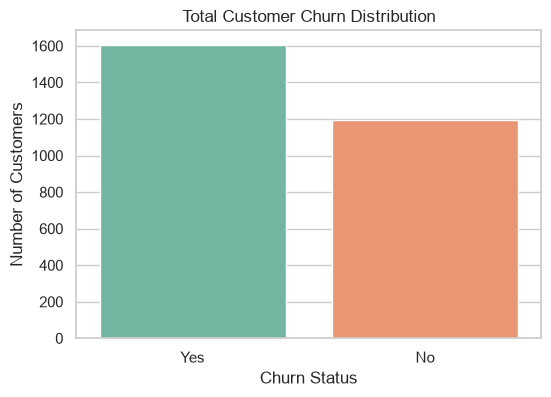

--- Churn Breakdown ---
churn
Yes    1605
No     1195
Name: count, dtype: int64

--- Churn Percentage ---
churn
Yes    57.321429
No     42.678571
Name: proportion, dtype: float64


In [25]:
# Plot overall churn count
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='churn', hue='churn', palette='Set2', legend=False)
plt.title('Total Customer Churn Distribution')
plt.xlabel('Churn Status')
plt.ylabel('Number of Customers')
plt.show()

# Print natin yung exact numbers and percentages
churn_counts = df['churn'].value_counts()
churn_percentage = df['churn'].value_counts(normalize=True) * 100
print("--- Churn Breakdown ---")
print(churn_counts)
print("\n--- Churn Percentage ---")
print(churn_percentage)

### Key Takeaway: Baseline Churn Rate
* **Observation:** Out of 2,800 total subscribers, **1,605 customers (57.32%)** have canceled their subscriptions, compared to **1,195 active users (42.68%)**.
* **Business Impact:** Losing more than half of the customer base indicates a severe retention bottleneck. This **57.32%** figure serves as our benchmark subsequent analysis will isolate which pricing tiers, support friction levels, and usage behaviors push churn above this baseline.

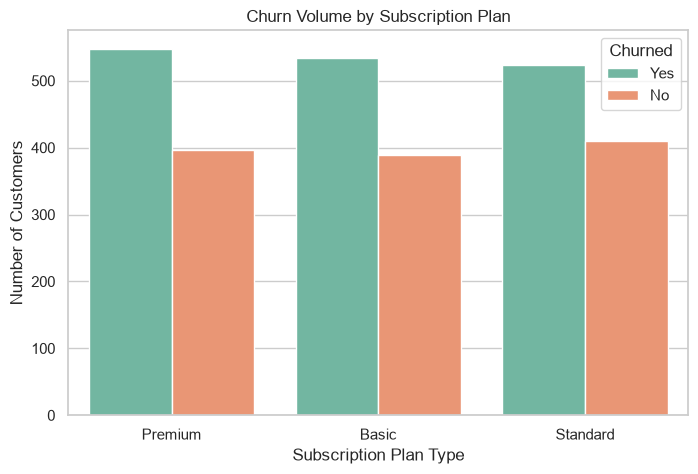

--- Churn Rate (%) by Subscription Plan ---
churn         No    Yes
plan_type              
Basic      42.15  57.85
Premium    41.95  58.05
Standard   43.94  56.06


In [26]:
# Plot churn volume by subscription plan
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='plan_type', hue='churn', palette='Set2')
plt.title('Churn Volume by Subscription Plan')
plt.xlabel('Subscription Plan Type')
plt.ylabel('Number of Customers')
plt.legend(title='Churned')
plt.show()

# Here we added pd.crosstab to print exact churn percentage within each plan tier
plan_churn_rate = pd.crosstab(df['plan_type'], df['churn'], normalize='index') * 100
print("--- Churn Rate (%) by Subscription Plan ---")
print(plan_churn_rate.round(2))

### Key Takeaway: Churn by Subscription Plan
* **Observation:** Churn rates are nearly identical across all tiers Premium leads slightly at 58.05%, followed by Basic at 57.85% and Standard at 56.06%.
* **So What:** Because every tier sits right near our 57.32% overall average, plan pricing alone isn't driving customers away. However, losing Premium subscribers hurts revenue the most, so retaining high-tier users should be a priority once we uncover the behavioral triggers.

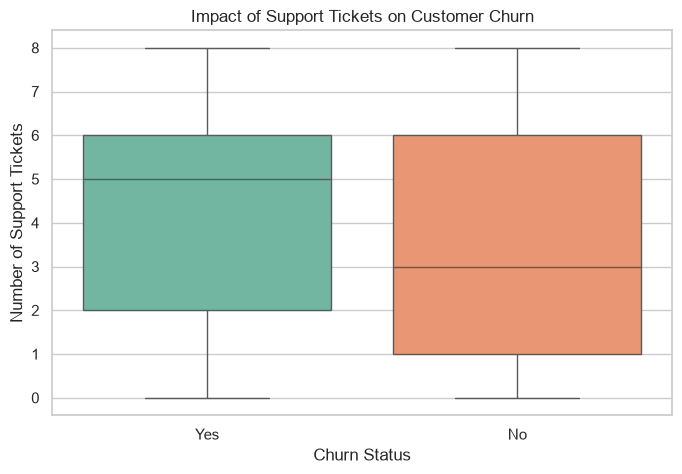

        count      mean       std  min  25%  50%  75%  max
churn                                                     
No     1195.0  3.435983  2.565369  0.0  1.0  3.0  6.0  8.0
Yes    1605.0  4.224299  2.586563  0.0  2.0  5.0  6.0  8.0


In [27]:
# Boxplot comparing support tickets for churned vs active users
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='churn', y='support_tickets', hue='churn', palette='Set2', legend=False)
plt.title('Impact of Support Tickets on Customer Churn')
plt.xlabel('Churn Status')
plt.ylabel('Number of Support Tickets')
plt.show()

# Print summary stats to get exact median and mean ticket counts
print(df.groupby('churn')['support_tickets'].describe())


### Key Takeaway: Support Friction vs. Churn
* **Observation:** Churned customers have a median of 5 support tickets (mean: 4.22), compared to a median of 3 tickets (mean: 3.44) for active users.
* **So What:** High support volume is a clear red flag for cancellation. Flagging accounts for proactive outreach as soon as they log their 4th support ticket could help resolve issues before users decide to leave.

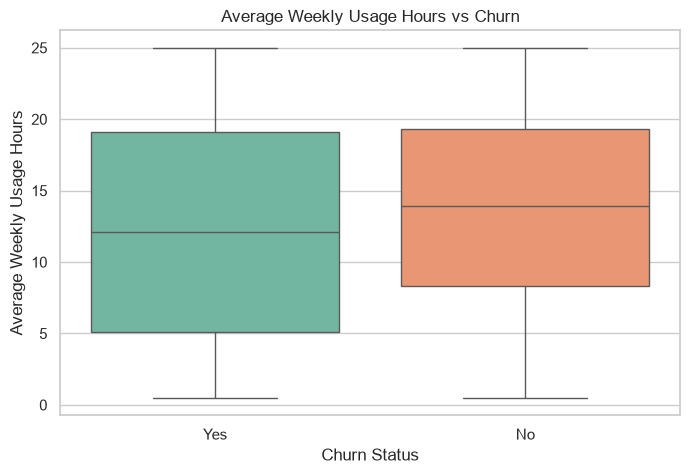

        count       mean       std  min   25%   50%   75%   max
churn                                                          
No     1195.0  13.746444  6.609131  0.5  8.35  13.9  19.3  25.0
Yes    1605.0  12.254829  7.398706  0.5  5.10  12.1  19.1  25.0


In [28]:
# Boxplot comparing weekly usage hours for churned vs active users
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='churn', y='avg_weekly_usage_hours', hue='churn', palette='Set2', legend=False)
plt.title('Average Weekly Usage Hours vs Churn')
plt.xlabel('Churn Status')
plt.ylabel('Average Weekly Usage Hours')
plt.show()

# Print summary stats for usage hours
print(df.groupby('churn')['avg_weekly_usage_hours'].describe())

### Key Takeaway: Product Engagement vs. Churn
* **Observation:** Churned users average 12.25 weekly usage hours (median: 12.1), down from 13.75 hours (median: 13.9) for active subscribers. Additionally, 25% of churned users log 5.1 hours or less per week.
* **So What:** Usage dropping below 8 hours per week and especially under 5 hours signals low product adoption. Triggering automated onboarding tips or check-in emails when weekly usage dips below 6 hours can help re-engage at-risk accounts.

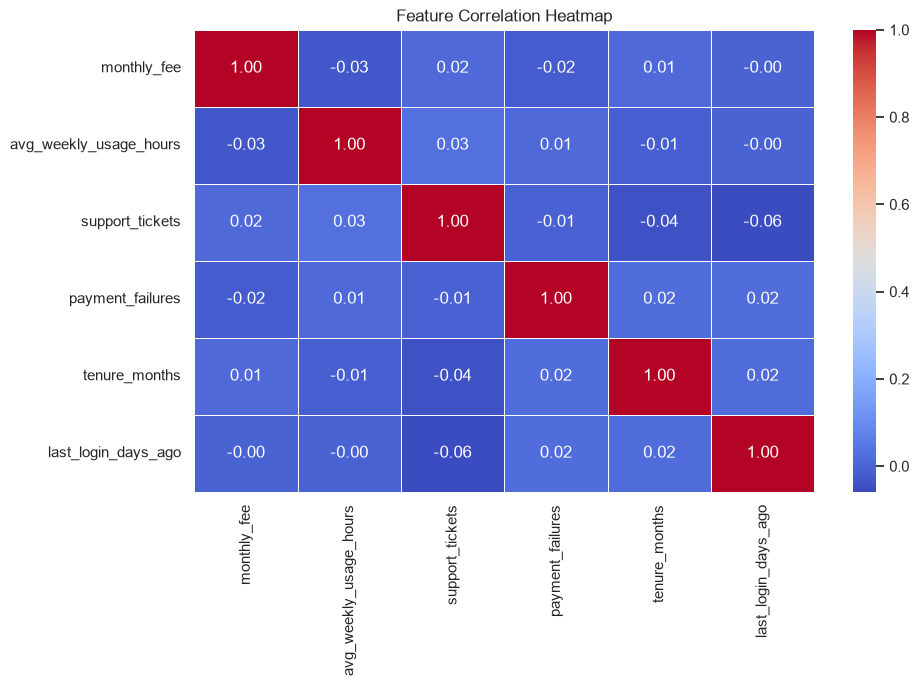

In [29]:
# Calculate correlation matrix for numerical business metrics (excluding user_id)
plt.figure(figsize=(10, 6))
numeric_df = df.drop(columns=['user_id']).select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Feature Correlation Heatmap')
plt.show()

In [30]:
# Check overlap between high payment failures (2+) and high support tickets (5+)
overlap_mask = (df["payment_failures"] >= 2) & (df["support_tickets"] >= 5)
overlap_count = df.loc[overlap_mask, "user_id"].nunique()
print(f"Customers with 2+ payment failures AND 5+ support tickets: {overlap_count}")

Customers with 2+ payment failures AND 5+ support tickets: 808


### Key Takeaway: Feature Correlation Heatmap

* **Observation:** Linear correlations among the numeric features are near zero, ranging from -0.06 (`support_tickets` vs. `last_login_days_ago`) to 0.03 (`avg_weekly_usage_hours` vs. `support_tickets`), and the matrix excludes the text-based `churn` target. However, cross-tabulating high-risk thresholds reveals that **808 customers (28.86% of the dataset)** experienced **both** 2+ payment failures and 5+ support tickets.
* **So What:** Near-zero linear correlation does not establish independence or mean that billing friction and support issues affect completely separate user groups. Because nearly a third of subscribers experience both issues simultaneously, we still track engagement, support volume, and payment failures as distinct visuals in Power BI to isolate their individual inflection points while accounting for compounded churn risk.


In [31]:
# Compare median and mean across remaining numerical metrics by churn status
remaining_metrics = ['payment_failures', 'tenure_months', 'last_login_days_ago']
print("--- Median Values by Churn Status ---")
print(df.groupby('churn')[remaining_metrics].median())

print("\n--- Mean Values by Churn Status ---")
print(df.groupby('churn')[remaining_metrics].mean().round(2))

--- Median Values by Churn Status ---
       payment_failures  tenure_months  last_login_days_ago
churn                                                      
No                  2.0           18.0                 22.0
Yes                 3.0           18.0                 34.0

--- Mean Values by Churn Status ---
       payment_failures  tenure_months  last_login_days_ago
churn                                                      
No                 2.07          18.59                26.15
Yes                2.80          18.63                32.88


### Key Takeaway: Billing Friction, Inactivity, and Tenure

- **Observation:** Churned users show a median of 34.0 days since their last login (vs. 22.0 days for active users) and 3.0 median payment failures (vs. 2.0 for active users).
- **So What:** Median tenure was 18 months for both active and churned customers, whereas higher churn risk is associated with inactivity past 30 days and repeated billing failures. Because cross-sectional snapshot data establishes behavioral association rather than proven causation, automated re-engagement nudges at day 25 of inactivity and proactive failed-payment recovery after the 2nd failure should be evaluated as proposed interventions via A/B testing.

In [32]:
# Exact churn breakdown tables for payment failures and support tickets
for col in ['payment_failures', 'support_tickets']:
    breakdown = (
        df.groupby(col)
          .agg(
              total_customers=('user_id', 'count'),
              churned_customers=('churn', lambda s: (s == 'Yes').sum())
          )
          .reset_index()
    )
    raw_share = breakdown['churned_customers'] / breakdown['total_customers'] * 100
    breakdown['churn_share_pct'] = raw_share.round(2)
    breakdown['pp_change'] = raw_share.diff().round(2)
    print(f"\n=== Churn Breakdown by {col} ===")
    display(breakdown)


=== Churn Breakdown by payment_failures ===


,payment_failures,total_customers,churned_customers,churn_share_pct,pp_change
0,0,442,175,39.59,NaN
1,1,496,199,40.12,0.53
2,2,478,307,64.23,24.10
3,3,471,316,67.09,2.87
4,4,453,301,66.45,-0.65
5,5,460,307,66.74,0.29



=== Churn Breakdown by support_tickets ===


,support_tickets,total_customers,churned_customers,churn_share_pct,pp_change
0,0,345,158,45.80,NaN
1,1,343,178,51.90,6.10
2,2,306,154,50.33,-1.57
3,3,304,153,50.33,0.00
4,4,284,159,55.99,5.66
5,5,294,200,68.03,12.04
6,6,345,220,63.77,-4.26
7,7,289,185,64.01,0.25
8,8,290,198,68.28,4.26


## Summary

- **Baseline Churn:** 57.32% (1,605 of 2,800 subscribers).
- **Non-Drivers:** Subscription tier (`plan_type`) shows a nearly flat churn share across plans, and median tenure was 18 months in both groups.
- **Top 4 Associated Churn Drivers:**
  1. **Account Inactivity:** Last login exceeding 30 days (median 34 days for churned users vs. 22 days for active users).
  2. **Support Friction:** Reaching 4 to 5+ support tickets (median 5 tickets vs. 3 for active; churn share ranges from 45.80%–55.99% across 0–4 tickets before rising to 68.03% at 5 tickets).
  3. **Billing Failures:** The largest single-step jump occurs between 1 failed payment (199 of 496, 40.12%) and 2 failed payments (307 of 478, 64.23%)—a 24.10 percentage-point increase. Among 1,862 customers with two or more failed payments, 1,231 (66.11%) were marked churned. Of those 1,862 customers, 808 also had five or more support tickets.
  4. **Low Weekly Usage:** Dropping below 8 hours/week (25% of churned users log 5.1 hours or less).
- **Proposed Interventions to A/B Test:** Because this dataset is a cross-sectional snapshot, these findings reflect behavioral associations rather than proven causation. Priority experiments include testing proactive billing recovery workflows immediately after a **2nd failed payment** and automated re-engagement nudges after **25 days of inactivity**.